# Projet 10 – Prédire l'attrition des employés (ESN)
## Étape 1 : Analyse exploratoire des données

**Objectif :** comprendre les données RH, les nettoyer, puis identifier les facteurs liés au départ des salariés (`a_quitte_l_entreprise`).

**Plan du notebook**
1. Exploration des 3 fichiers (SIRH, évaluation, sondage)
2. Jointure et nettoyage → un seul DataFrame
3. Analyse du fichier central (statistiques et graphiques)

---
## 1. Exploration des fichiers
### 1.1 Fichier SIRH (`extrait_sirh.csv`)
Données administratives : âge, genre, poste, revenu, ancienneté…

In [1]:
import pandas as pd

sirh = pd.read_csv("data/extrait_sirh.csv")

print(sirh.shape)
sirh.head()

(1470, 12)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


In [2]:
sirh.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   id_employee                     1470 non-null   int64
 1   age                             1470 non-null   int64
 2   genre                           1470 non-null   str  
 3   revenu_mensuel                  1470 non-null   int64
 4   statut_marital                  1470 non-null   str  
 5   departement                     1470 non-null   str  
 6   poste                           1470 non-null   str  
 7   nombre_experiences_precedentes  1470 non-null   int64
 8   nombre_heures_travailless       1470 non-null   int64
 9   annee_experience_totale         1470 non-null   int64
 10  annees_dans_l_entreprise        1470 non-null   int64
 11  annees_dans_le_poste_actuel     1470 non-null   int64
dtypes: int64(8), str(4)
memory usage: 137.9 KB


In [3]:
sirh.describe()

,id_employee,age,revenu_mensuel,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000
mean,1024.865306,36.923810,6502.931293,2.693197,80.0,11.279592,7.008163,4.229252
std,602.024335,9.135373,4707.956783,2.498009,0.0,7.780782,6.126525,3.623137
min,1.000000,18.000000,1009.000000,0.000000,80.0,0.000000,0.000000,0.000000
25%,491.250000,30.000000,2911.000000,1.000000,80.0,6.000000,3.000000,2.000000
50%,1020.500000,36.000000,4919.000000,2.000000,80.0,10.000000,5.000000,3.000000
75%,1555.750000,43.000000,8379.000000,4.000000,80.0,15.000000,9.000000,7.000000
max,2068.000000,60.000000,19999.000000,9.000000,80.0,40.000000,40.000000,18.000000


In [4]:
for col in ["genre", "statut_marital", "departement", "poste"]:
    print(sirh[col].value_counts(), "\n")

genre
M    882
F    588
Name: count, dtype: int64 

statut_marital
Marié(e)       673
Célibataire    470
Divorcé(e)     327
Name: count, dtype: int64 

departement
Consulting             961
Commercial             446
Ressources Humaines     63
Name: count, dtype: int64 

poste
Cadre Commercial           326
Assistant de Direction     292
Consultant                 259
Tech Lead                  145
Manager                    131
Senior Manager             102
Représentant Commercial     83
Directeur Technique         80
Ressources Humaines         52
Name: count, dtype: int64 



**À retenir (SIRH) :** 1 470 employés, aucune valeur manquante. Variables catégorielles : genre, statut marital, département, poste, domaine d'étude.

### 1.2 Fichier évaluation (`extrait_eval.csv`)
Satisfaction, note d'évaluation, heures supplémentaires, etc.

In [5]:
eval_df = pd.read_csv("data/extrait_eval.csv")

print(eval_df.shape)
eval_df.head()

(1470, 10)


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


In [6]:
print(eval_df.shape)
eval_df.info()

(1470, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   satisfaction_employee_environnement        1470 non-null   int64
 1   note_evaluation_precedente                 1470 non-null   int64
 2   niveau_hierarchique_poste                  1470 non-null   int64
 3   satisfaction_employee_nature_travail       1470 non-null   int64
 4   satisfaction_employee_equipe               1470 non-null   int64
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64
 6   eval_number                                1470 non-null   str  
 7   note_evaluation_actuelle                   1470 non-null   int64
 8   heure_supplementaires                      1470 non-null   str  
 9   augementation_salaire_precedente           1470 non-null   str  
dtypes: int64(7), str(3)
memory usage: 115.0 KB


In [7]:
print(eval_df.describe())

       satisfaction_employee_environnement  note_evaluation_precedente  \
count                          1470.000000                 1470.000000   
mean                              2.721769                    2.729932   
std                               1.093082                    0.711561   
min                               1.000000                    1.000000   
25%                               2.000000                    2.000000   
50%                               3.000000                    3.000000   
75%                               4.000000                    3.000000   
max                               4.000000                    4.000000   

       niveau_hierarchique_poste  satisfaction_employee_nature_travail  \
count                1470.000000                           1470.000000   
mean                    2.063946                              2.728571   
std                     1.106940                              1.102846   
min                     1.000000     

In [8]:
print(eval_df["heure_supplementaires"].value_counts())
print(eval_df["augementation_salaire_precedente"].unique())

heure_supplementaires
Non    1054
Oui     416
Name: count, dtype: int64
<StringArray>
['11 %', '23 %', '15 %', '12 %', '13 %', '20 %', '22 %', '21 %', '17 %',
 '14 %', '16 %', '18 %', '19 %', '24 %', '25 %']
Length: 15, dtype: str


**À retenir (évaluation) :** 1 470 employés, aucune valeur manquante. `heure_supplementaires` est en Oui/Non et la colonne d'augmentation de salaire est stockée en texte : à convertir.

### 1.3 Fichier sondage (`extrait_sondage.csv`)
Contient la variable cible `a_quitte_l_entreprise`, ainsi que des informations sur les déplacements, la formation, etc.

In [9]:
sondage = pd.read_csv("data/extrait_sondage.csv")

print(sondage.shape)
sondage.head()

(1470, 12)


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


In [10]:
sondage.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   a_quitte_l_entreprise                1470 non-null   str  
 1   nombre_participation_pee             1470 non-null   int64
 2   nb_formations_suivies                1470 non-null   int64
 3   nombre_employee_sous_responsabilite  1470 non-null   int64
 4   code_sondage                         1470 non-null   int64
 5   distance_domicile_travail            1470 non-null   int64
 6   niveau_education                     1470 non-null   int64
 7   domaine_etude                        1470 non-null   str  
 8   ayant_enfants                        1470 non-null   str  
 9   frequence_deplacement                1470 non-null   str  
 10  annees_depuis_la_derniere_promotion  1470 non-null   int64
 11  annes_sous_responsable_actuel        1470 non-null   int64
dtypes: 

In [11]:
print(sondage.describe())

       nombre_participation_pee  nb_formations_suivies  \
count               1470.000000            1470.000000   
mean                   0.793878               2.799320   
std                    0.852077               1.289271   
min                    0.000000               0.000000   
25%                    0.000000               2.000000   
50%                    1.000000               3.000000   
75%                    1.000000               3.000000   
max                    3.000000               6.000000   

       nombre_employee_sous_responsabilite  code_sondage  \
count                               1470.0   1470.000000   
mean                                   1.0   1024.865306   
std                                    0.0    602.024335   
min                                    1.0      1.000000   
25%                                    1.0    491.250000   
50%                                    1.0   1020.500000   
75%                                    1.0   1555.750000 

In [12]:
for col in ["a_quitte_l_entreprise", "domaine_etude", "ayant_enfants", "frequence_deplacement"]:
    print(sondage[col].value_counts(), "\n")

a_quitte_l_entreprise
Non    1233
Oui     237
Name: count, dtype: int64 

domaine_etude
Infra & Cloud              606
Transformation Digitale    464
Marketing                  159
Entrepreunariat            132
Autre                       82
Ressources Humaines         27
Name: count, dtype: int64 

ayant_enfants
Y    1470
Name: count, dtype: int64 

frequence_deplacement
Occasionnel    1043
Frequent        277
Aucun           150
Name: count, dtype: int64 



**À retenir (sondage) :** variable cible déséquilibrée : **1 233 restés (83,9 %) / 237 partis (16,1 %)**. Il faudra en tenir compte pour la modélisation (stratification, métriques recall / F1 / AUC plutôt que l'accuracy). Certaines colonnes sont constantes et seront supprimées.

---
## 2. Jointure et nettoyage
### 2.1 Création d'une clé commune
Les 3 fichiers n'ont pas le même identifiant : `id_employee` (SIRH), `eval_number` (évaluation, format texte) et `code_sondage` (sondage). On extrait l'identifiant numérique de `eval_number` pour obtenir une clé `id_employee`.

In [13]:
eval_df["id_employee"] = eval_df["eval_number"].apply(lambda x: int(x.replace("E_", "")))

In [14]:
ids_sirh = set(sirh["id_employee"])
ids_eval = set(eval_df["id_employee"])
ids_sondage = set(sondage["code_sondage"])

print(ids_sirh == ids_eval == ids_sondage)
print(len(ids_sirh), len(ids_eval), len(ids_sondage))
print(sirh["id_employee"].is_unique, eval_df["id_employee"].is_unique, sondage["code_sondage"].is_unique)

True
1470 1470 1470
True True True


Les identifiants sont identiques dans les 3 fichiers : la jointure ne perdra aucune ligne.

### 2.2 Jointure
On fusionne les 3 fichiers avec un `left join` à partir du SIRH. Les 3 fichiers ayant exactement les mêmes 1 470 identifiants, aucune ligne n'est perdue.

In [15]:
df = (
    sirh
    .merge(eval_df, on="id_employee", how="left")
    .merge(sondage, left_on="id_employee", right_on="code_sondage", how="left")
)

print(df.shape)
df.head()

(1470, 34)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,...,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,...,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,...,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,...,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,...,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


### 2.3 Conversion de l'augmentation de salaire
La colonne contient du texte (ex. « 12 % »). On retire le symbole `%` et on convertit en nombre.

In [16]:
df["augementation_salaire_precedente"] = df["augementation_salaire_precedente"].apply(
    lambda x: float(x.replace("%", "").strip())
)

df["augementation_salaire_precedente"].head()

0    11.0
1    23.0
2    15.0
3    11.0
4    12.0
Name: augementation_salaire_precedente, dtype: float64

### 2.4 Encodage des colonnes Oui/Non
`a_quitte_l_entreprise` et `heure_supplementaires` sont transformées en `0` (Non) / `1` (Oui), format exploitable par les modèles.

In [17]:
df["a_quitte_l_entreprise"] = df["a_quitte_l_entreprise"].map({"Non": 0, "Oui": 1})
df["heure_supplementaires"] = df["heure_supplementaires"].map({"Non": 0, "Oui": 1})

print(df["a_quitte_l_entreprise"].value_counts())
print(df["heure_supplementaires"].value_counts())

a_quitte_l_entreprise
0    1233
1     237
Name: count, dtype: int64
heure_supplementaires
0    1054
1     416
Name: count, dtype: int64


### 2.5 Suppression des colonnes inutiles et correction des noms
- Suppression des colonnes constantes ou redondantes (`nombre_heures_travailless`, `nombre_employee_sous_responsabilite`, `ayant_enfants`) et des clés devenues inutiles (`code_sondage`, `eval_number`).
- Correction de deux noms mal orthographiés.

**Résultat :** un DataFrame de 1 470 lignes et 29 colonnes.

In [18]:
df = df.drop(columns=[
    "nombre_heures_travailless",           # constante (80)
    "nombre_employee_sous_responsabilite", # constante (1)
    "ayant_enfants",                       # constante (Y)
    "code_sondage",                        # doublon de id_employee
    "eval_number",                         # doublon de id_employee
])

df = df.rename(columns={
    "augementation_salaire_precedente": "augmentation_salaire_precedente",
    "annes_sous_responsable_actuel": "annees_sous_responsable_actuel",
})

print(df.shape)
print(df.columns.tolist())

(1470, 29)
['id_employee', 'age', 'genre', 'revenu_mensuel', 'statut_marital', 'departement', 'poste', 'nombre_experiences_precedentes', 'annee_experience_totale', 'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel', 'satisfaction_employee_environnement', 'note_evaluation_precedente', 'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso', 'note_evaluation_actuelle', 'heure_supplementaires', 'augmentation_salaire_precedente', 'a_quitte_l_entreprise', 'nombre_participation_pee', 'nb_formations_suivies', 'distance_domicile_travail', 'niveau_education', 'domaine_etude', 'frequence_deplacement', 'annees_depuis_la_derniere_promotion', 'annees_sous_responsable_actuel']


---
## 3. Analyse du fichier central
### 3.1 Statistiques moyennes selon le départ
Comparaison des moyennes entre les employés restés (0) et partis (1).

In [19]:
df.groupby("a_quitte_l_entreprise").mean(numeric_only=True).T

a_quitte_l_entreprise,0,1
id_employee,1027.656123,1010.345992
age,37.561233,33.607595
revenu_mensuel,6832.739659,4787.092827
nombre_experiences_precedentes,2.645580,2.940928
annee_experience_totale,11.862936,8.244726
annees_dans_l_entreprise,7.369019,5.130802
annees_dans_le_poste_actuel,4.484185,2.902954
satisfaction_employee_environnement,2.771290,2.464135
note_evaluation_precedente,2.770479,2.518987
niveau_hierarchique_poste,2.145985,1.637131


**Conclusion :** les partis ont en moyenne un revenu, un âge et une ancienneté plus faibles, et des scores de satisfaction légèrement inférieurs.

### 3.2 Graphique 1 : taux de départ selon les heures supplémentaires

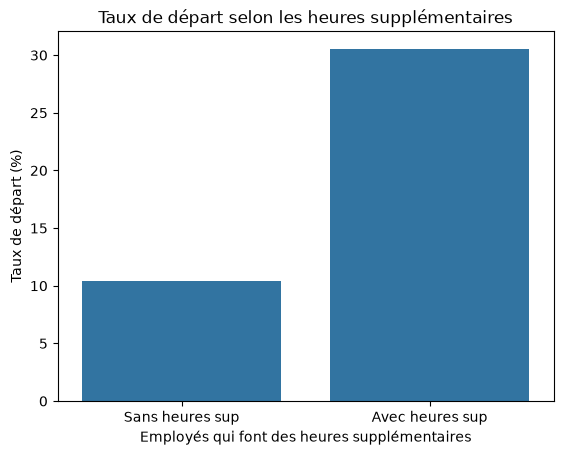

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

taux = df.groupby("heure_supplementaires")["a_quitte_l_entreprise"].mean() * 100

sns.barplot(x=taux.index, y=taux.values)
plt.xticks([0, 1], ["Sans heures sup", "Avec heures sup"])
plt.ylabel("Taux de départ (%)")
plt.xlabel("Employés qui font des heures supplémentaires")
plt.title("Taux de départ selon les heures supplémentaires")
plt.show()

**Conclusion :** les heures supplémentaires sont associées à plus de départs : ≈ 10 % de départs sans heures sup contre ≈ 30 % avec. 53,6 % des partis en faisaient, contre 23,4 % des restés.

### 3.3 Graphique 2 : revenu mensuel selon le départ

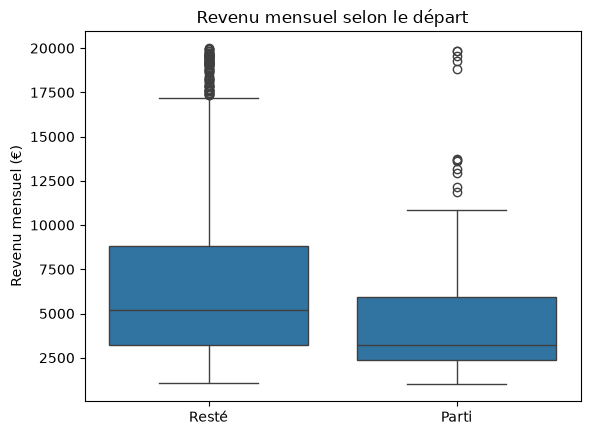

In [21]:
sns.boxplot(data=df, x="a_quitte_l_entreprise", y="revenu_mensuel")
plt.xticks([0, 1], ["Resté", "Parti"])
plt.xlabel("")
plt.ylabel("Revenu mensuel (€)")
plt.title("Revenu mensuel selon le départ")
plt.show()

**Conclusion :** les employés partis ont un revenu médian nettement plus bas (≈ 3 200 € contre ≈ 5 200 €). Les valeurs extrêmes repérées par la méthode IQR sont **conservées** car elles correspondent à des salaires plausibles (postes de direction).

### 3.4 Distribution des salaires

<Axes: xlabel='revenu_mensuel', ylabel='Count'>

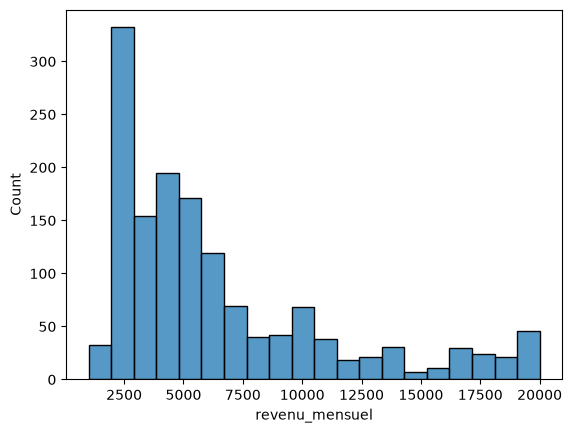

In [22]:
sns.histplot(df["revenu_mensuel"])

**Conclusion :** la distribution du revenu est **étalée vers la droite** (quelques très hauts salaires).

### 3.5 Matrice de corrélation

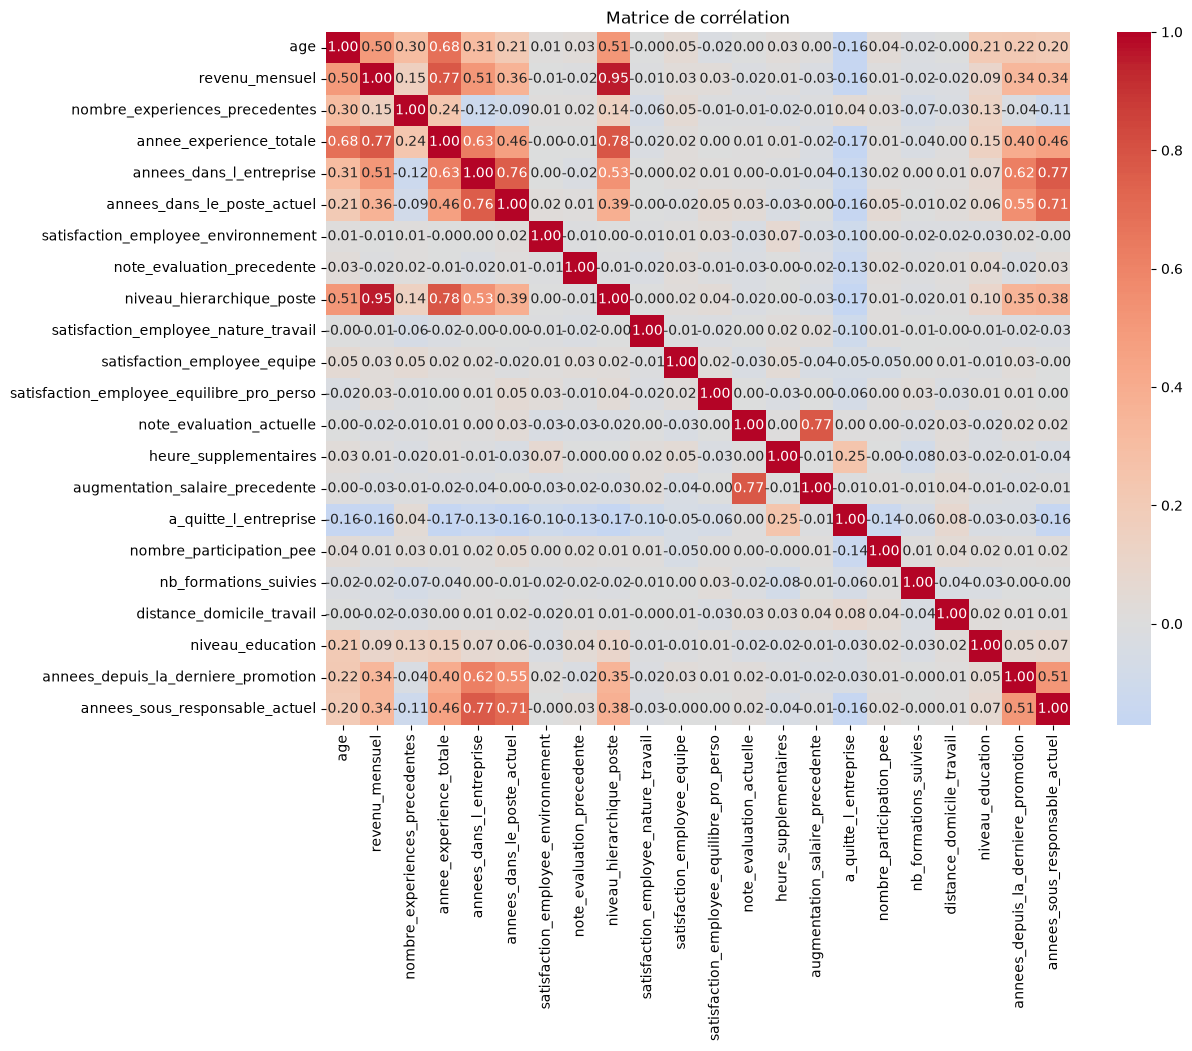

In [23]:
plt.figure(figsize=(12, 9))
corr = df.drop(columns="id_employee").corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

**Conclusion :**
- `revenu_mensuel` et `niveau_hierarchique` sont très corrélés (≈ 0,95) : variables **redondantes** à surveiller.
- Les corrélations avec la cible sont toutes faibles (max ≈ +0,25 pour `heure_supplementaires`) : pas de variable explicative unique, d'où l'intérêt d'un modèle combinant plusieurs variables.
- Aucun lien visible avec `note_evaluation_actuelle` ni `augmentation_salaire_precedente`.

### 3.6 Graphique 3 : âge selon le départ (variable quantitative vs qualitative)

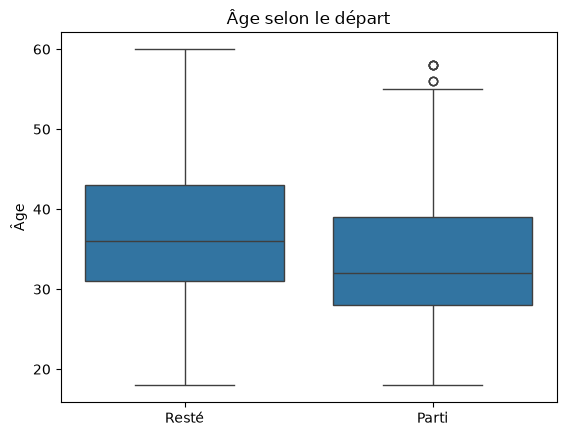

In [24]:
sns.boxplot(data=df, x="a_quitte_l_entreprise", y="age")
plt.xticks([0, 1], ["Resté", "Parti"])
plt.xlabel("")
plt.ylabel("Âge")
plt.title("Âge selon le départ")
plt.show()

**Conclusion :** les employés partis sont plus jeunes (âge médian ≈ 32 ans contre ≈ 36 ans).

### 3.7 Graphique 4 : taux de départ par poste

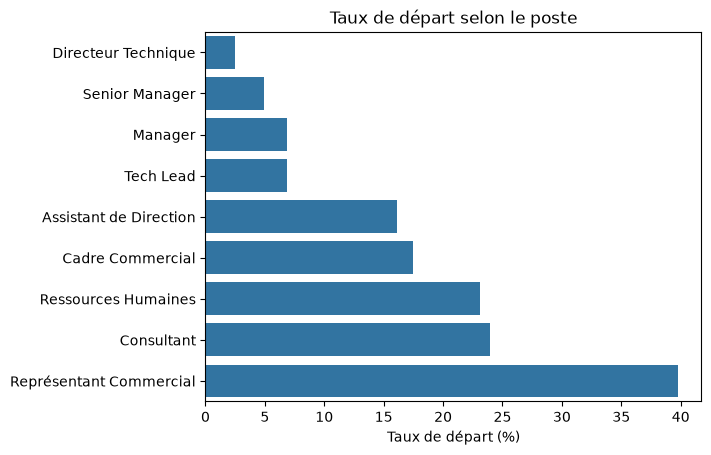

poste
Directeur Technique         2.5
Senior Manager              4.9
Manager                     6.9
Tech Lead                   6.9
Assistant de Direction     16.1
Cadre Commercial           17.5
Ressources Humaines        23.1
Consultant                 23.9
Représentant Commercial    39.8
Name: a_quitte_l_entreprise, dtype: float64


In [25]:
taux_poste = (df.groupby("poste")["a_quitte_l_entreprise"].mean() * 100).sort_values()

sns.barplot(x=taux_poste.values, y=taux_poste.index)
plt.xlabel("Taux de départ (%)")
plt.ylabel("")
plt.title("Taux de départ selon le poste")
plt.show()

print(taux_poste.round(1))

**Conclusion :** le poste est un facteur discriminant fort. Les Représentants Commerciaux (≈ 40 %) et les Consultants (≈ 24 %) concentrent les départs, alors que les postes d'encadrement sont très stables (Directeur Technique ≈ 2,5 %, Senior Manager ≈ 5 %). Le taux élevé en RH (≈ 23 %) repose sur seulement 52 personnes : à interpréter avec prudence.

---
## 4. Synthèse de l'étape 1
- **Données :** 1 470 employés, 29 variables après nettoyage, aucune valeur manquante.
- **Cible déséquilibrée :** 16,1 % de départs → stratification et métriques adaptées (recall, F1, AUC).
- **Facteurs associés au départ :** heures supplémentaires, revenu faible, jeune âge, postes commerciaux / consultants.
- **Points d'attention :** `revenu_mensuel` ≈ `niveau_hierarchique` (redondance), distribution des salaires asymétrique.

**Prochaine étape :** préparation des données et modélisation.